In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [90]:
import importlib
import functions_jules
importlib.reload(functions_jules)

from functions_jules import *  # this re-imports the updated names into the namespace


In [ ]:
import numpy as np
import pandas as pd

# Simulation parameters
T = 2000                  # Number of time steps
d = 2                     # Number of regimes
k = 6                     # Number of exogenous variables
true_exo_idxs = [2, 5]    # Indices of truly active exogenous variables (0-based)
phi = 0.8                 # AR(1) persistence for exogenous variables

# MS-ARCH-X regime-dependent parameters
omega = [0.1, 0.3]              # ω_1, ω_2
alpha = [0.2, 0.4]              # α_1, α_2
gamma = np.zeros((d, k))       # γ_{s,j}
gamma[0, 2] = 0.7               # X_3 is active in regime 0
gamma[1, 5] = 0.6              # X_6 is active in regime 1

# Markov transition matrix
P = np.array([[0.99, 0.01],
              [0.03, 0.97]])

# Initial regime probabilities
pi_0 = np.array([0.5, 0.5])


In [92]:
def simulate_regime_sequence(T, P, pi_0):
    """
    Simulates a Markov regime sequence S_t of length T
    given a transition matrix P and initial distribution pi_0.

    Parameters:
    - T (int): Length of the time series
    - P (np.ndarray): d x d transition matrix
    - pi_0 (np.ndarray): initial regime probabilities

    Returns:
    - S (np.ndarray): array of regime indices (length T)
    """
    d = P.shape[0]
    S = np.zeros(T, dtype=int)
    S[0] = np.random.choice(d, p=pi_0)

    for t in range(1, T):
        S[t] = np.random.choice(d, p=P[S[t-1]])

    return S


In [93]:
def simulate_exogenous_variables(T, k, phi=0.8, seed=None):
    """
    Simulates k exogenous AR(1) processes over T time steps.

    Parameters:
    - T (int): number of time steps
    - k (int): number of exogenous variables
    - phi (float): AR(1) coefficient
    - seed (int or None): random seed for reproducibility

    Returns:
    - X (np.ndarray): T x k matrix of exogenous variables
    """
    if seed is not None:
        np.random.seed(seed)
    
    X = np.zeros((T, k))
    for j in range(k):
        for t in range(1, T):
            X[t, j] = phi * X[t - 1, j] + np.random.normal(0, 1)

    return X


In [94]:
def simulate_returns(S, X, omega, alpha, gamma):
    """
    Simulate volatility and returns for a MS-ARCH-X model with additive exogenous variables.

    Parameters:
    - S (np.ndarray): regime sequence of length T
    - X (np.ndarray): exogenous variables, shape (T, k)
    - omega (list or array): length-d list of ω_s
    - alpha (list or array): length-d list of α_s
    - gamma (np.ndarray): shape (d, k) array of exogenous coefficients per regime

    Returns:
    - returns (np.ndarray): simulated return series
    - sigma2 (np.ndarray): conditional variances σ_t²
    """
    T, k = X.shape
    d = len(omega)
    
    sigma2 = np.zeros(T)
    returns = np.zeros(T)
    
    for t in range(1, T):
        s = S[t]
        gamma_s = gamma[s]
        exo_term = np.dot(gamma_s, X[t])
        sigma2[t] = omega[s] + alpha[s] * returns[t-1]**2 + exo_term
        sigma2[t] = max(sigma2[t], 1e-6)  # ensure strictly positive variance
        returns[t] = np.random.normal(0, np.sqrt(sigma2[t]))

    return returns, sigma2


In [95]:
def package_simulated_data(returns, X, sigma2, S):
    """
    Packages simulated returns, exogenous variables, and metadata into a DataFrame.

    Parameters:
    - returns (np.ndarray): simulated return series, length T
    - X (np.ndarray): exogenous variables, shape (T, k)
    - sigma2 (np.ndarray): true conditional variances
    - S (np.ndarray): regime sequence

    Returns:
    - data (pd.DataFrame): formatted for calibrate_and_store
    - metadata (dict): includes true regimes and volatilities
    """
    T, k = X.shape
    data_dict = {'eps': returns}
    for j in range(k):
        data_dict[f'X_{j+1}'] = X[:, j]

    # DataFrame for calibrate_and_store
    data = pd.DataFrame(data_dict)

    # Metadata (not used for estimation, just for evaluation)
    metadata = {
        'sigma2': sigma2,
        'regimes': S
    }

    return data, metadata


In [96]:
from collections import defaultdict

def run_msarchx_simulation_and_estimation(T=2000, d=2, k=6, seed=42, folder="SimulatedResults"):
    """
    Simulates MS-ARCH-X data with additive exogenous influence and runs calibrate_and_store.

    Parameters:
    - T (int): Number of time steps
    - d (int): Number of regimes
    - k (int): Number of exogenous variables
    - seed (int): Random seed for reproducibility
    - folder (str): Folder name to store results

    Returns:
    - store (dict): Output from calibrate_and_store
    - metadata (dict): True volatility and regime sequence
    """
    np.random.seed(seed)

    # --- Define true model parameters ---
    true_exo_idxs = [2, 5]
    omega = [0.1, 0.3]
    alpha = [0.2, 0.4]
    gamma = np.zeros((d, k))
    gamma[0, 2] = 0.7
    gamma[1, 5] = 0.6
    P = np.array([[0.95, 0.05],
                  [0.10, 0.90]])
    pi_0 = np.array([0.5, 0.5])

    # --- Simulate data ---
    S = simulate_regime_sequence(T, P, pi_0)
    X = simulate_exogenous_variables(T, k, phi=0.8)
    returns, sigma2 = simulate_returns(S, X, omega, alpha, gamma)
    data, metadata = package_simulated_data(returns, X, sigma2, S)

    # --- Run estimation using your pipeline ---

    store = calibrate_and_store(
        data=data,
        targets=['eps'],
        indicators=[['X_1', 'X_2', 'X_3', 'X_4', 'X_5', 'X_6']],
        niter_HMM=1000,
        niter_MS=1000,
        niter_X=500,
        d=d,
        q=1,
        additive_method='absolute',
        folder=folder
    )

    return store, metadata


100%|██████████| 1000/1000 [02:36<00:00,  6.38it/s]


No exogen transition


/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/functions.py:651: RuntimeWarning:

divide by zero encountered in log

100%|██████████| 1000/1000 [02:36<00:00,  6.38it/s]


No exogen transition


mu of dimension 2: will depend on delta



/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning:

Values in x were outside bounds during a minimize step, clipping to bounds


/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning:

Values in x were outside bounds during a minimize step, clipping to bounds




















































































































































































































































































































































































































































































































100%|██████████| 500/500 [05:15<00:00,  1.59it/s]
/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/functions.p

No exogen transition


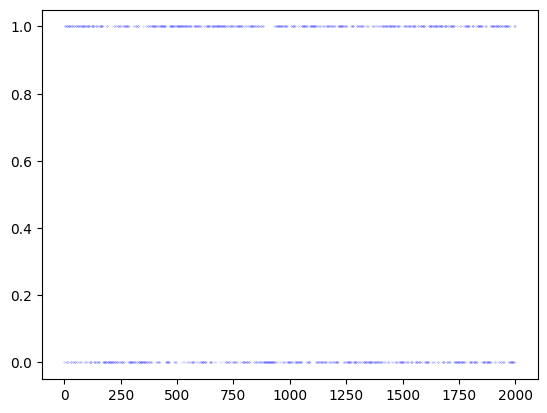

In [97]:
store_output, simulation_metadata = run_msarchx_simulation_and_estimation()

In [98]:
store_output['eps']['X_1+X_2+X_3+X_4+X_5+X_6']['final_result']


{'P': array([[0.73704319, 0.26295681],
        [0.18744234, 0.81255766]]),
 'beta': array([[[ 0.01815798, -0.01815798, -0.12092853,  0.12092853,
           0.03765285, -0.03765285],
         [-0.01819238,  0.01819238,  0.12088806, -0.12088806,
          -0.03766202,  0.03766202]],
 
        [[-0.00065978,  0.00065978, -0.05574368,  0.05574368,
           0.02791018, -0.02791018],
         [ 0.00064374, -0.00064374,  0.05575169, -0.05575169,
          -0.02790639,  0.02790639]]]),
 'omega': array([0.001     , 0.51732361]),
 'alpha': array([[0.        , 0.39528581]]),
 'mu': array([[0., 0.],
        [0., 0.]]),
 'pi_0': array([1.e+00, 1.e-10]),
 'log-likelihood': -256.12323191455334,
 'exogen_transition': array([[ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
          0.        ],
        [-0.87798259, -1.56785943, -0.97276452,  1.67974738, -0.62754   ,
         -1.48397906],
        [-1.52926642, -0.90757756, -0.37158958,  1.68590395, -2.55551855,
          0.26474338

In [99]:
# Path used in calibrate_and_store
key = '(X_1+X_2+X_3+X_4+X_5+X_6)' 
store_output['eps'][key]['final_result']['exogen_additive']

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        ],
       [0.87798259, 1.56785943, 0.97276452, 1.67974738, 0.62754   ,
        1.48397906],
       [1.52926642, 0.90757756, 0.37158958, 1.68590395, 2.55551855,
        0.26474338],
       ...,
       [1.5831164 , 2.0341951 , 1.54190716, 0.61202507, 2.36384414,
        0.52656158],
       [1.23066754, 1.13539918, 0.25273772, 1.16089019, 3.18733202,
        0.03105666],
       [0.45307948, 2.23637623, 0.94213423, 1.67473611, 2.77338938,
        1.09925057]])

In [100]:
stored_data = load_stored_results(folder='SimulatedResults')
print(stored_data)

defaultdict(<function load_stored_results.<locals>.<lambda> at 0x12a16d670>, {'eps': {'No Exogenous': {'eps': array([ 0.        , -0.0010836 ,  0.70338411, ...,  0.10732019,
       -0.41626143, -0.69852072]), 'dates': Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999],
      dtype='int64', length=2000), 'target': 'eps', 'indicator': 'No Exogenous', 'initial_params': {'P': array([[0.7820543 , 0.2179457 ],
       [0.17467783, 0.82532217]]), 'omega': array([0.001     , 0.76913137]), 'alpha': array([[0.        , 0.44167262]]), 'pi_0': array([1.e+00, 1.e-10]), 'log-likelihood': -289.36406781480963}, 'result': {0: {'pi_0': array([1.e+00, 1.e-10]), 'P': array([[0.77993453, 0.22006547],
       [0.17984219, 0.82015781]]), 'beta': None, 'omega': array([0.001     , 0.81129372]), 'alpha': array([[0.       , 0.4298856]]), 'predicted_states': array([0, 0, 1, ..., 1, 1, 1]), 'log-likelihood': -289.8597648767

In [105]:
# Path used in calibrate_and_store
key = '(X_1+X_2+X_3+X_4+X_5+X_6)' 
result = store_output['eps'][key]['final_result']

gamma_est = result['mu']  # shape (k, d) — each column = one regime

def display_gamma_coefficients(gamma_est):
    k, d = gamma_est.shape
    df = pd.DataFrame(gamma_est, columns=[f'Regime {i}' for i in range(d)])
    df.index = [f'X_{i+1}' for i in range(k)]
    return df

gamma_df = display_gamma_coefficients(result['mu'])
pd.DataFrame(gamma_df)

,Regime 0,Regime 1
X_1,0.0,0.0
X_2,0.0,0.0


In [102]:
result['alpha']

array([[0.        , 0.39528581]])

In [103]:
log_liks = [r['log-likelihood'] for r in store_output['eps'][key]['result']]
plt.plot(log_liks)
plt.title("Log-likelihood over EM iterations")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.grid(True)
plt.show()


In [ ]:
states = store_output['eps'][key]['states sequence']
unique, counts = np.unique(states, return_counts=True)
print("Predicted regime counts:", dict(zip(unique, counts)))


Predicted regime counts: {np.int64(0): np.int64(928), np.int64(1): np.int64(1072)}


In [ ]:
X = result['exogen_additive']
sigma2 = simulation_metadata['sigma2']


regimes = states
regime_0_avg_sigma2 = sigma2[regimes == 0].mean()
regime_1_avg_sigma2 = sigma2[regimes == 1].mean()

print("Avg σ² in regime 0:", regime_0_avg_sigma2)
print("Avg σ² in regime 1:", regime_1_avg_sigma2)


Avg σ² in regime 0: 0.04580304432274055
Avg σ² in regime 1: 1.3417215094781945


> **Note / next step:** condititions initaile avec MS-ARCH --> trouve lambda avec initals conditions, switch lambda